In [27]:
import json
import pandas as pd
from pathlib import Path
import seaborn as sns

In [28]:
streams = pd.read_parquet("../data/processed/streams_clean.parquet")
tag_cache = json.loads(Path("../data/cache/artist_tags.json").read_text())
len(streams), len(tag_cache)

(57200, 3341)

In [29]:
rows = [
    {"artist": artist, "tag": t['name'].lower(), "count": t['count']}
     for artist, tags in tag_cache.items()
     for t in tags
]

tags_df = pd.DataFrame(rows)
print(len(tags_df), "artist-tag rows", tags_df['tag'].nunique(), "distinct tags")

26406 artist-tag rows 3394 distinct tags


In [30]:
print(tags_df['tag'].value_counts().head(30))

plays = streams["artist"].value_counts().rename("plays")
tags_df = tags_df.merge(plays, left_on="artist", right_index=True, how="left")
tags_df.groupby("tag")["plays"].sum().sort_values(ascending=False).head(30)

tag
electronic           1024
hip-hop               882
american              850
rap                   786
pop                   660
hip hop               624
trap                  504
usa                   481
indie                 347
female vocalists      326
house                 320
rock                  317
rnb                   314
dance                 294
alternative           291
dubstep               289
british               263
instrumental          228
classical             221
indie pop             216
united states         216
soul                  208
singer-songwriter     185
composer              182
edm                   154
all                   151
experimental          148
alternative rock      141
electronica           132
folk                  130
Name: count, dtype: int64


tag
electronic          32074
american            22839
trap                20811
hip-hop             18047
hip hop             16762
rap                 16464
dubstep             15981
house               10209
usa                  9669
future bass          7889
dance                7551
pop                  7491
brostep              7177
edm                  7003
electro house        5221
rnb                  5064
electro              4786
electronica          4607
bass                 4456
all                  4376
female vocalists     3842
australian           3585
united states        3540
chillout             3437
good                 3289
instrumental         3258
british              3244
riddim               3182
california           3067
drum and bass        3041
Name: plays, dtype: int64

In [31]:
GENERIC = {"electronic", "electronica", "edm", "dance", "pop"}

MACRO_MAP = {
    # bass music
    "dubstep": "bass music", "brostep": "bass music", "riddim": "bass music",
    "future bass": "bass music", "bass": "bass music", "trap": "bass music",
    "drum and bass": "bass music",
    # house / dance
    "house": "house/dance", "electro house": "house/dance", "electro": "house/dance",
    "deep house": "house/dance", "progressive house": "house/dance",
    "fidget house": "house/dance", "edm": "house/dance", "dance": "house/dance",
    # electronic (everything else electronic)
    "electronic": "electronic", "electronica": "electronic",
    "chillout": "electronic", "ambient": "electronic", "downtempo": "electronic",
    # hip-hop / rap
    "hip-hop": "hip-hop/rap", "hip hop": "hip-hop/rap", "rap": "hip-hop/rap",
    # r&b / soul
    "rnb": "r&b/soul", "soul": "r&b/soul", "funk": "r&b/soul",
    # pop
    "pop": "pop", "indie pop": "pop", "synthpop": "pop",
    # indie / rock
    "indie": "indie/rock", "rock": "indie/rock", "alternative": "indie/rock",
    "alternative rock": "indie/rock", "indie rock": "indie/rock",
    # quieter corners
    "classical": "classical/score", "soundtrack": "classical/score",
    "folk": "folk/acoustic", "singer-songwriter": "folk/acoustic",
}

In [32]:
def assign_genre(tags):
    ordered = sorted(tags, key=lambda t: -t["count"])
    mappable = [t["name"].lower() for t in ordered if t["name"].lower() in MACRO_MAP]
    specific = [t for t in mappable if t not in GENERIC]
    pick = specific or mappable          # falls back to generic if that's all there is
    return MACRO_MAP[pick[0]] if pick else "other"

artist_genre = pd.Series({a: assign_genre(t) for a, t in tag_cache.items()}, name="genre")
artist_genre.value_counts()

genre
hip-hop/rap        762
other              496
bass music         434
indie/rock         377
house/dance        292
classical/score    235
r&b/soul           234
electronic         216
pop                182
folk/acoustic      113
Name: count, dtype: int64

In [33]:
plays_per_artist = streams["artist"].value_counts()
genre_share = plays_per_artist.groupby(artist_genre).sum().sort_values(ascending=False)
print((genre_share / genre_share.sum()).round(3))

other_artists = artist_genre[artist_genre == "other"].index
plays_per_artist[plays_per_artist.index.isin(other_artists)].head(15)

genre
bass music         0.388
hip-hop/rap        0.259
house/dance        0.113
electronic         0.061
classical/score    0.045
indie/rock         0.043
other              0.033
r&b/soul           0.027
pop                0.025
folk/acoustic      0.007
Name: count, dtype: float64


artist
RemK               88
Know Good          68
Ecchi.mp4          52
Kahrise            46
Seth David         45
RÜFÜS DU SOL       36
Ailow              31
Big Florida        30
Holmesick          29
SPORTMODE          28
sumthin sumthin    27
Jhay Rivas         27
Dj Bountyhunter    24
YONKER DILLA       24
HAVEN.             23
Name: count, dtype: int64

In [34]:
streams = streams.merge(artist_genre, left_on="artist", right_index=True, how="left")
streams["genre"] = streams["genre"].fillna("other")
streams["genre"].value_counts(normalize=True).round(3)

genre
bass music         0.388
hip-hop/rap        0.259
house/dance        0.113
electronic         0.061
classical/score    0.045
indie/rock         0.043
other              0.033
r&b/soul           0.027
pop                0.025
folk/acoustic      0.007
Name: proportion, dtype: float64

Text(0.5, 1.0, 'Listening hours by genre, 2021–2026')

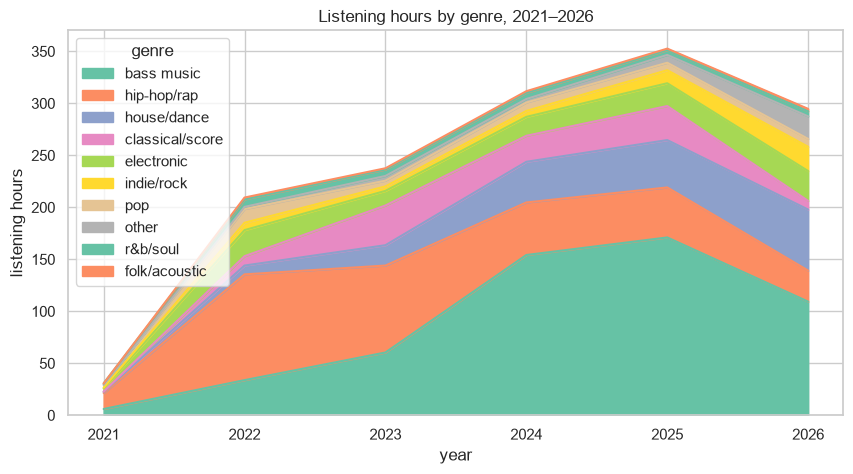

In [44]:
streams["year"] = streams["ts"].dt.year
hours = streams.pivot_table(index="year", columns="genre", values="ms_played", aggfunc="sum") / 3.6e6
hours = hours[hours.sum().sort_values(ascending=False).index]   # order columns biggest-first
hours.round(1)

sns.set_theme(style="whitegrid", palette="Set2")

ax = hours.plot.area(figsize=(10, 5))
ax.set_ylabel("listening hours")
ax.set_title("Listening hours by genre, 2021–2026")

In [36]:
streams["hour"] = streams["ts"].dt.hour
streams["dow"] = streams["ts"].dt.day_name()
streams["month"] = streams["ts"].dt.to_period("M").dt.to_timestamp()
streams["is_listen"] = streams["ms_played"] >= 30_000

/var/folders/27/_tq5d72j46145d36gzkszr800000gn/T/ipykernel_76176/4196144712.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  streams["month"] = streams["ts"].dt.to_period("M").dt.to_timestamp()


In [37]:
streams = streams.sort_values("ts").reset_index(drop=True)
prev_end = (streams["ts"] + pd.to_timedelta(streams["ms_played"], unit="ms")).shift()
gap = streams["ts"] - prev_end
streams["session_id"] = (gap > pd.Timedelta(minutes=30)).cumsum()

In [38]:
sess_min = streams.groupby("session_id")["ms_played"].sum() / 60000
print(len(sess_min), "sessions | median", round(sess_min.median(), 1),
      "min | longest", round(sess_min.max() / 60, 1), "hours")

3158 sessions | median 17.2 min | longest 6.2 hours


In [39]:
out = Path("../data/processed/streams_enriched.parquet")
streams.to_parquet(out)
print(out.exists(), pd.read_parquet(out).shape)

True (57200, 29)


In [40]:
marathon = streams.groupby("session_id")["ms_played"].sum().idxmax()
streams.loc[streams["session_id"] == marathon, ["ts", "artist", "track"]].head(10)

,ts,artist,track
35488,2025-06-10 11:24:55-05:00,A$AP Rocky,Wild for the Night (feat. Skrillex & Birdy Nam...
35489,2025-06-10 11:24:56-05:00,Childish Gambino,This Is America
35490,2025-06-10 11:28:34-05:00,Maxo Kream,"BIG PERSONA (feat. Tyler, The Creator)"
35491,2025-06-10 11:31:06-05:00,JAY-Z,Gotta Have It
35492,2025-06-10 11:31:31-05:00,Lil Wayne,Mona Lisa (feat. Kendrick Lamar)
35493,2025-06-10 11:31:32-05:00,NGHTMRE,Torch
35494,2025-06-10 11:32:13-05:00,Kendrick Lamar,HUMBLE.
35495,2025-06-10 11:32:14-05:00,Rick Ross,Hustlin'
35496,2025-06-10 11:36:49-05:00,Kanye West,New Slaves
35497,2025-06-10 11:43:43-05:00,Kanye West,Mercy.1
